# 05 Error analysis

Where the final model is weak, and what seems to be behind it. Only validation is used. Probabilities are calibrated with Platt out of fold: each half of the validation expeditions is calibrated by a model learned on the other half, on non-anomalous rows only.

`gap` is the predicted minus the actual share of summits, so a positive gap means the model was too optimistic. Fields known only after the climb (`TERMREASON`, `MPERHIGHPT`) help explain errors here and are never used as features. No individual climbers are listed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

from src import models as M
from src.config import PROCESSED_DIR, TABLES_DIR, TARGET
from src.data_dictionary import parse_guide
from src.error_analysis import group_report, reliability_table, residual_icc, season_gaps, within_group_auc
from src.evaluate import add_age_bins, evaluate, fmt, paired_difference
from src.features import to_number
from src.leakage_audit import with_post_climb_fields
from src.split import dev_split, fit_frame, load_features
from src.style import BLUE, GRID, INK, MUTED, ORANGE, apply_style, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
apply_style()

final = M.load_final_config()
exped = pd.read_parquet(PROCESSED_DIR / "exped.parquet")
members = pd.read_parquet(PROCESSED_DIR / "members.parquet")
peaks = pd.read_parquet(PROCESSED_DIR / "peaks.parquet")
train, val = dev_split(load_features())
train_fit = fit_frame(train)
val = with_post_climb_fields(val, exped, members)
clean = ~val["ANOMALOUS_SEASON"].to_numpy(dtype=bool)
y = M.target(val)
model = M.refit_lightgbm(train_fit, final["iterations"], params=final["params"], features=final["features"], seeds=tuple(final["seeds"]))
p_raw = model.predict(val)
p = M.crossfit_calibrate(val, p_raw, "platt", fit_rows=clean)
PEAK_NAMES = {**peaks.set_index("PEAKID")["PKNAME"].to_dict(), "OTHER": "Other peaks"}
print(f"val rows {len(val):,}, expeditions {val['EXPID'].nunique():,}, success {y.mean():.3f}")
print(f"raw: AUC {roc_auc_score(y, p_raw):.3f}, Brier {brier_score_loss(y, p_raw):.3f}, log loss {log_loss(y, p_raw):.3f}, mean p {p_raw.mean():.3f}")
print(f"calibrated: AUC {roc_auc_score(y, p):.3f}, Brier {brier_score_loss(y, p):.3f}, log loss {log_loss(y, p):.3f}, mean p {p.mean():.3f}")

val rows 5,042, expeditions 922, success 0.537
raw: AUC 0.712, Brier 0.216, log loss 0.622, mean p 0.496
calibrated: AUC 0.712, Brier 0.216, log loss 0.620, mean p 0.556


## 1. Interval width
Climbers on the same peak in the same season share weather and route conditions, so resampling whole seasons gives a wider interval than resampling expeditions. We repeat the comparisons with the other models at both levels, because a win that holds only for expeditions would not mean much.

In [2]:
levels = {"expedition": val["EXPID"].astype(str),
          "peak x year x season": val["PEAK_GROUP"].astype(str) + "|" + val["YEAR"].astype(str) + "|" + val["SEASON"].astype(str),
          "year x season": val["YEAR"].astype(str) + "|" + val["SEASON"].astype(str)}
intervals = pd.DataFrame({name: {"groups": keys.nunique(), **fmt(evaluate(y, p_raw, keys.to_numpy(), n_boot=1000))} for name, keys in levels.items()}).T
intervals.to_csv(TABLES_DIR / "05_intervals.csv")
display(intervals)

p_logreg = M.fit_logreg(train_fit).predict(val)
p_rule = M.PeakSeasonRate().fit(train_fit).predict(val)
cv_catboost = M.cv_catboost(train_fit, params=M.DEFAULT_CATBOOST)
p_catboost = M.refit_catboost(train_fit, int(cv_catboost["iterations"].mean()), params=M.DEFAULT_CATBOOST).predict(val)
rows = []
for name, other in (("logreg", p_logreg), ("peak x season rule", p_rule), ("CatBoost typical", p_catboost)):
    for level in ("expedition", "peak x year x season"):
        rows.append({"LightGBM minus": name, "resampled by": level, **fmt(paired_difference(y, p_raw, other, levels[level].to_numpy(), n_boot=1000), digits=4)})
paired = pd.DataFrame(rows).set_index(["LightGBM minus", "resampled by"])
paired.to_csv(TABLES_DIR / "05_paired_by_level.csv")
display(paired)

,groups,roc_auc,brier,log_loss
expedition,922,"0.712 [0.683, 0.739]","0.216 [0.209, 0.224]","0.622 [0.605, 0.640]"
peak x year x season,95,"0.712 [0.652, 0.760]","0.216 [0.199, 0.232]","0.622 [0.585, 0.657]"
year x season,12,"0.712 [0.654, 0.751]","0.216 [0.201, 0.232]","0.622 [0.589, 0.655]"


roc_auc                       brier                    log_loss
LightGBM minus     resampled by                                                                                          
logreg             expedition             0.0257 [0.0112, 0.0392]  -0.0117 [-0.0182, -0.0052]  -0.0340 [-0.0513, -0.0169]
                   peak x year x season  0.0257 [-0.0030, 0.0510]   -0.0117 [-0.0266, 0.0004]  -0.0340 [-0.0765, -0.0023]
peak x season rule expedition             0.1108 [0.0846, 0.1390]  -0.0331 [-0.0410, -0.0253]  -0.0708 [-0.0874, -0.0538]
                   peak x year x season   0.1108 [0.0553, 0.1572]  -0.0331 [-0.0504, -0.0122]  -0.0708 [-0.1064, -0.0271]
CatBoost typical   expedition             0.0225 [0.0081, 0.0377]  -0.0078 [-0.0115, -0.0039]  -0.0175 [-0.0261, -0.0088]
                   peak x year x season  0.0225 [-0.0028, 0.0550]   -0.0078 [-0.0152, 0.0002]  -0.0175 [-0.0333, -0.0007]

## 2. Years
2020 and spring 2021 are anomalous seasons (COVID), and the model was not fitted on anomalous seasons.

,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss,mean_p_raw
YEAR,,,,,,,,,,,
2018,1708,344,0.578,0.552,-0.026,0.737,0.694,0.775,0.203,0.591,0.494
2019,1833,358,0.597,0.571,-0.027,0.740,0.700,0.778,0.199,0.583,0.509
2020,136,21,0.699,0.456,-0.242,0.612,0.454,0.768,0.276,0.757,0.413
2021,1365,199,0.387,0.550,0.163,0.675,0.621,0.727,0.247,0.691,0.491


without anomalous seasons: AUC 0.737, Brier 0.206, log loss 0.598 (4,236 rows)
anomalous seasons only: AUC 0.595, Brier 0.266, log loss 0.734 (806 rows)


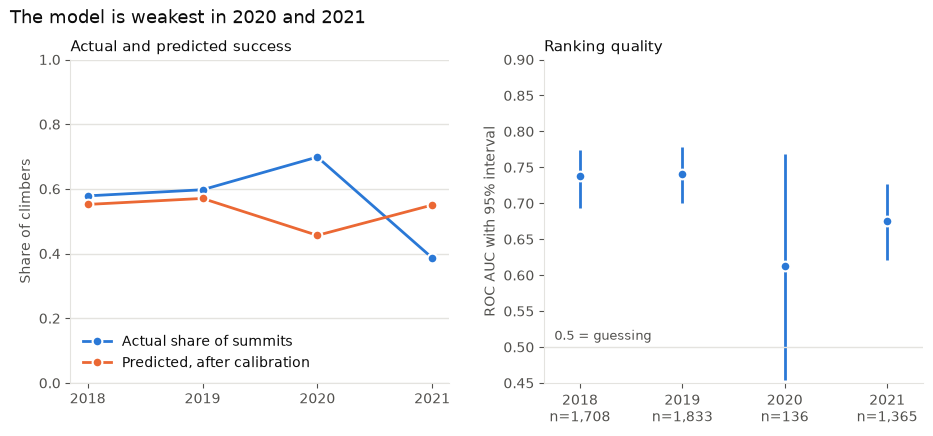

In [3]:
by_year = group_report(val, p, "YEAR", n_boot=1000)
by_year["mean_p_raw"] = pd.Series(p_raw).groupby(val["YEAR"].astype(str).to_numpy()).mean().reindex(by_year.index)
by_year.round(3).to_csv(TABLES_DIR / "05_by_year.csv")
display(by_year.round(3))
print(f"without anomalous seasons: AUC {roc_auc_score(y[clean], p[clean]):.3f}, Brier {brier_score_loss(y[clean], p[clean]):.3f}, log loss {log_loss(y[clean], p[clean]):.3f} ({int(clean.sum()):,} rows)")
print(f"anomalous seasons only: AUC {roc_auc_score(y[~clean], p[~clean]):.3f}, Brier {brier_score_loss(y[~clean], p[~clean]):.3f}, log loss {log_loss(y[~clean], p[~clean]):.3f} ({int((~clean).sum()):,} rows)")

years = by_year.index.astype(int).to_numpy()
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.25})
left.plot(years, by_year["mean_y"], color=BLUE, lw=2, marker="o", ms=7, mec="white", mew=1.5, label="Actual share of summits")
left.plot(years, by_year["mean_p"], color=ORANGE, lw=2, marker="o", ms=7, mec="white", mew=1.5, label="Predicted, after calibration")
left.set_ylim(0, 1)
left.set_xticks(years)
left.set_ylabel("Share of climbers")
left.legend(frameon=False, loc="lower left", labelcolor=INK)
left.grid(axis="y", color=GRID, lw=1)
left.set_axisbelow(True)
left.set_title("Actual and predicted success", loc="left", fontsize=11)
right.errorbar(years, by_year["roc_auc"], yerr=[by_year["roc_auc"] - by_year["auc_low"], by_year["auc_high"] - by_year["roc_auc"]], fmt="o", ms=7, color=BLUE, mec="white", mew=1.5, capsize=0, lw=2)
right.axhline(0.5, color=GRID, lw=1)
right.text(years[0] - 0.25, 0.51, "0.5 = guessing", color=MUTED, fontsize=9)
right.set_xticks(years, [f"{year}\nn={int(n):,}" for year, n in zip(years, by_year["n"])])
right.set_xlim(years[0] - 0.35, years[-1] + 0.35)
right.set_ylim(0.45, 0.9)
right.set_ylabel("ROC AUC with 95% interval")
right.set_title("Ranking quality", loc="left", fontsize=11)
fig.suptitle("The model is weakest in 2020 and 2021", x=0.07, y=1.0, ha="left", fontsize=13, color=INK)
save_figure(fig, "05_by_year.png")
plt.show()

## 3. Peaks
`success_2010_2017` helps to see whether a large gap comes from a peak that has changed since the last training years.

,name,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss,success_2010_2017
PEAK_GROUP,,,,,,,,,,,,
EVER,Everest,1510,232,0.669,0.715,0.046,0.707,0.665,0.750,0.197,0.579,0.602
AMAD,Ama Dablam,1041,189,0.540,0.574,0.034,0.655,0.616,0.690,0.232,0.655,0.469
MANA,Manaslu,687,107,0.531,0.539,0.008,0.678,0.598,0.747,0.227,0.646,0.431
OTHER,Other peaks,439,113,0.394,0.388,-0.006,0.717,0.611,0.808,0.204,0.596,0.341
LHOT,Lhotse,263,73,0.479,0.592,0.113,0.544,0.441,0.645,0.274,0.750,0.383
HIML,Himlung Himal,262,47,0.378,0.398,0.020,0.621,0.549,0.714,0.228,0.649,0.370
CHOY,Cho Oyu,192,38,0.625,0.496,-0.129,0.631,0.482,0.780,0.244,0.678,0.372
DHA1,Dhaulagiri I,162,29,0.185,0.351,0.166,0.718,0.607,0.824,0.164,0.505,0.243
BARU,Baruntse,101,20,0.228,0.249,0.021,0.817,0.598,0.972,0.135,0.435,0.247


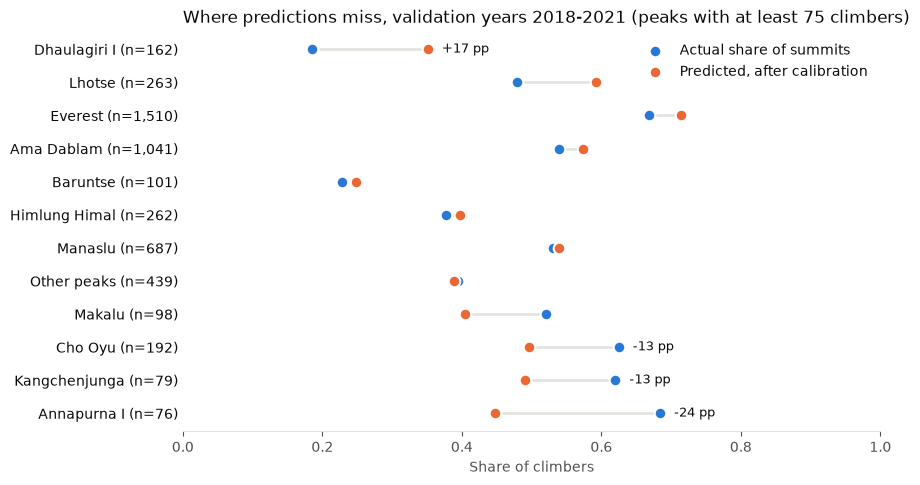

In [4]:
by_peak = group_report(val, p, "PEAK_GROUP")
recent = train[train["YEAR"] >= 2010]
by_peak["success_2010_2017"] = recent[TARGET].astype(float).groupby(recent["PEAK_GROUP"].astype(str)).mean().reindex(by_peak.index)
by_peak.insert(0, "name", [PEAK_NAMES.get(k, k) for k in by_peak.index])
by_peak = by_peak.sort_values("n", ascending=False)
by_peak.round(3).to_csv(TABLES_DIR / "05_by_peak.csv")
display(by_peak.round(3))

shown = by_peak[by_peak["n"] >= 75].sort_values("gap")
fig, ax = plt.subplots(figsize=(9, 5.2))
rows = np.arange(len(shown))
ax.hlines(rows, shown["mean_y"], shown["mean_p"], color=GRID, lw=2, zorder=1)
ax.scatter(shown["mean_y"], rows, s=70, color=BLUE, edgecolors="white", linewidths=1.5, zorder=3, label="Actual share of summits")
ax.scatter(shown["mean_p"], rows, s=70, color=ORANGE, edgecolors="white", linewidths=1.5, zorder=3, label="Predicted, after calibration")
ax.set_yticks(rows, [f"{name} (n={int(n):,})" for name, n in zip(shown["name"], shown["n"])], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of climbers")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
extremes = shown["gap"].abs().sort_values(ascending=False).index[:4]
for row, key in zip(rows, shown.index):
    if key in extremes:
        ax.text(max(shown.loc[key, "mean_y"], shown.loc[key, "mean_p"]) + 0.02, row, f"{100 * shown.loc[key, 'gap']:+.0f} pp", va="center", color=INK, fontsize=9)
ax.legend(frameon=False, loc="upper right", labelcolor=INK)
ax.set_title("Where predictions miss, validation years 2018-2021 (peaks with at least 75 climbers)", loc="left", fontsize=12)
save_figure(fig, "05_by_peak.png")
plt.show()

## 4. Season, age, sex, experience and peak type

In [5]:
seasons = {"1": "Spring", "2": "Summer", "3": "Autumn", "4": "Winter"}
prior = to_number(val["PRIOR_EXPEDITIONS"])
heights = to_number(val["HEIGHTM"])
views = val.assign(
    SEASON_NAME=val["SEASON"].astype(str).map(seasons),
    AGE_GROUP=add_age_bins(val),
    SEX_KNOWN=val["SEX"].astype("string").fillna("unknown"),
    EXPERIENCE=np.select([prior.isna(), prior == 0, prior < 5], ["unknown", "first expedition", "1-4 earlier"], "5 or more earlier"),
    PEAK_TYPE=np.select([val["PEAKID"] == "EVER", heights >= 8000], ["Everest", "Other 8000 m"], "Below 8000 m"),
    ROUTE_TYPE=np.where(val["COMRTE"].astype(bool), "commercial route", "other route"))
tables = {column: group_report(views, p, column) for column in ("SEASON_NAME", "AGE_GROUP", "SEX_KNOWN", "EXPERIENCE", "PEAK_TYPE", "ROUTE_TYPE")}
pd.concat(tables, names=["view", "group"]).round(3).to_csv(TABLES_DIR / "05_by_group.csv")
for name, table in tables.items():
    print(name)
    display(table.round(3))

SEASON_NAME


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
SEASON_NAME,,,,,,,,,,
Autumn,2592,468,0.505,0.499,-0.006,0.687,0.653,0.721,0.223,0.637
Spring,2372,433,0.581,0.620,0.040,0.728,0.687,0.769,0.207,0.600
Winter,78,21,0.244,0.472,0.229,0.600,0.343,0.848,0.233,0.648


AGE_GROUP


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
AGE_GROUP,,,,,,,,,,
25-34,1111,528,0.599,0.601,0.003,0.699,0.652,0.745,0.213,0.615
35-44,1514,621,0.581,0.605,0.024,0.707,0.669,0.744,0.213,0.612
45-54,1361,583,0.509,0.522,0.013,0.688,0.648,0.730,0.224,0.639
55+,774,401,0.386,0.418,0.031,0.702,0.654,0.747,0.211,0.610
<25,228,139,0.566,0.649,0.084,0.652,0.548,0.790,0.232,0.658
unknown,54,20,0.741,0.649,-0.091,0.843,0.575,0.953,0.133,0.424


SEX_KNOWN


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
SEX_KNOWN,,,,,,,,,,
F,1008,481,0.589,0.587,-0.002,0.707,0.664,0.748,0.210,0.607
M,4033,878,0.524,0.548,0.024,0.711,0.684,0.738,0.217,0.623


... (2 outputs left out)

PEAK_TYPE


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
PEAK_TYPE,,,,,,,,,,
Below 8000 m,1973,398,0.458,0.472,0.014,0.707,0.672,0.741,0.217,0.621
Everest,1510,232,0.669,0.715,0.046,0.707,0.665,0.750,0.197,0.579
Other 8000 m,1559,292,0.509,0.508,-0.001,0.657,0.612,0.709,0.232,0.657


ROUTE_TYPE


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
ROUTE_TYPE,,,,,,,,,,
commercial route,3404,555,0.604,0.626,0.022,0.691,0.662,0.724,0.215,0.619
other route,1638,367,0.397,0.409,0.012,0.691,0.645,0.732,0.216,0.620


## 5. Ranking inside groups
The pooled AUC also rewards knowing which peak is easier. AUC inside one peak, one season or one expedition shows how well the model separates climbers facing the same conditions, and the intraclass correlation (ICC) of the errors shows how much of the error they share.

In [6]:
season_key = levels["peak x year x season"].to_numpy()
rows = [{"level": "all rows (pooled)", "auc": roc_auc_score(y, p_raw), "groups": 1, "rows": len(y), "error_icc": np.nan}]
for name, keys in (("inside one peak", val["PEAK_GROUP"].astype(str).to_numpy()), ("inside one peak x year x season", season_key), ("inside one expedition", val["EXPID"].astype(str).to_numpy())):
    rows.append({"level": name, **within_group_auc(y, p_raw, keys), "error_icc": residual_icc(y, p, keys)})
inside = pd.DataFrame(rows).set_index("level")
inside.round(3).to_csv(TABLES_DIR / "05_inside_groups.csv")
display(inside.round(3))

,auc,groups,rows,error_icc
level,,,,
all rows (pooled),0.712,1,5042,NaN
inside one peak,0.677,15,4997,0.024
inside one peak x year x season,0.672,52,4685,0.163
inside one expedition,0.657,370,2983,0.369


## 6. Seasons with mass failures
One peak in one season, with at least 30 climbers. A large positive gap is a season that went much worse than the model expected. `foresummit` is the share of rows whose expedition ended at a subpeak or foresummit (`TERMREASON` 2), which does not count as reaching the main peak.

In [7]:
gaps = season_gaps(val, p)
gaps.insert(0, "name", [PEAK_NAMES.get(k, k) for k in gaps["PEAK_GROUP"]])
foresummit = (to_number(val["TERMREASON"]) == 2).groupby([val["PEAK_GROUP"].astype(str), to_number(val["YEAR"]).astype(int), val["SEASON"].astype(int)]).mean()
gaps["foresummit"] = [foresummit.get((peak, int(year), int(season))) for peak, year, season in zip(gaps["PEAK_GROUP"].astype(str), gaps["YEAR"], gaps["SEASON"])]
gaps["SEASON"] = gaps["SEASON"].astype(str).map(seasons)
gaps.round(3).to_csv(TABLES_DIR / "05_season_gaps.csv", index=False)
print(f"seasons with at least 30 climbers: {len(gaps)}; gap above +20 pp: {int((gaps['gap'] > 0.2).sum())}; below -20 pp: {int((gaps['gap'] < -0.2).sum())}")
print("Worse than expected:")
display(gaps.head(8).round(3))
print("Better than expected:")
display(gaps.tail(8).iloc[::-1].round(3))

dev = pd.concat([train, val], ignore_index=True)
manaslu = dev[(dev["PEAKID"] == "MANA") & (dev["SEASON"] == 3) & (dev["YEAR"] >= 2014)].merge(exped[["EXPID", "YEAR", "TERMREASON"]], on=["EXPID", "YEAR"], how="left", suffixes=("", "_E"))
reason = "TERMREASON_E" if "TERMREASON_E" in manaslu else "TERMREASON"
manaslu_table = manaslu.assign(foresummit=to_number(manaslu[reason]) == 2, main_peak=to_number(manaslu[reason]) == 1).groupby("YEAR").agg(
    rows=(TARGET, "size"), success=(TARGET, lambda s: s.astype(float).mean()), foresummit=("foresummit", "mean"), ended_on_main_peak=("main_peak", "mean"))
manaslu_table.round(3).to_csv(TABLES_DIR / "05_manaslu_autumn.csv")
print("Manaslu in autumn, train and val years:")
display(manaslu_table.round(3))

foresummit_rows = ((val["PEAKID"] == "MANA") & (val["SEASON"] == 3) & (val["YEAR"] == 2021)).to_numpy()
year_2021 = (val["YEAR"] == 2021).to_numpy()
print(f"without Manaslu autumn 2021 ({int(foresummit_rows.sum())} rows): val AUC {roc_auc_score(y[~foresummit_rows], p_raw[~foresummit_rows]):.3f} (all rows {roc_auc_score(y, p_raw):.3f})")
rest_2021 = year_2021 & ~foresummit_rows
print(f"2021 without these rows: AUC {roc_auc_score(y[rest_2021], p_raw[rest_2021]):.3f} (with them {roc_auc_score(y[year_2021], p_raw[year_2021]):.3f}), actual {y[rest_2021].mean():.3f}, predicted {p[rest_2021].mean():.3f}")

seasons with at least 30 climbers: 32; gap above +20 pp: 5; below -20 pp: 6
Worse than expected:


,name,PEAK_GROUP,YEAR,SEASON,n,expeditions,mean_y,mean_p,gap,foresummit
0,Manaslu,MANA,2021,Autumn,189,21,0.063,0.520,0.457,0.878
1,Dhaulagiri I,DHA1,2021,Spring,39,6,0.000,0.409,0.409,0.000
2,Lhotse,LHOT,2021,Spring,88,23,0.341,0.641,0.300,0.000
3,Ama Dablam,AMAD,2019,Spring,49,13,0.204,0.430,0.226,0.000
4,Everest,EVER,2021,Spring,409,48,0.472,0.695,0.223,0.000
5,Other peaks,OTHER,2019,Spring,47,14,0.128,0.296,0.169,0.000
6,Other peaks,OTHER,2018,Spring,37,9,0.270,0.415,0.145,0.000
7,Himlung Himal,HIML,2021,Autumn,53,6,0.226,0.364,0.138,0.000


Better than expected:


,name,PEAK_GROUP,YEAR,SEASON,n,expeditions,mean_y,mean_p,gap,foresummit
31,Kangchenjunga,KANG,2019,Spring,30,5,0.933,0.490,-0.443,0.000
30,Putha Hiunchuli,PUTH,2019,Autumn,30,7,0.767,0.438,-0.329,0.000
29,Manaslu,MANA,2018,Autumn,198,30,0.768,0.478,-0.290,0.000
28,Makalu,MAKA,2019,Spring,54,9,0.759,0.478,-0.281,0.000
27,Everest,EVER,2020,Spring,31,2,0.710,0.472,-0.237,0.000
26,Annapurna I,ANN1,2021,Spring,50,7,0.720,0.494,-0.226,0.000
25,Dhaulagiri I,DHA1,2021,Autumn,44,7,0.568,0.415,-0.153,0.000
24,Cho Oyu,CHOY,2018,Autumn,90,16,0.711,0.566,-0.145,0.111


Manaslu in autumn, train and val years:


,rows,success,foresummit,ended_on_main_peak
YEAR,,,,
2014,103,0.583,0.000,0.825
2015,104,0.481,0.000,0.635
2016,157,0.096,0.592,0.242
2017,257,0.716,0.000,0.946
2018,198,0.768,0.000,0.934
2019,254,0.740,0.000,0.929
2020,18,0.722,0.000,1.000
2021,189,0.063,0.878,0.122


without Manaslu autumn 2021 (189 rows): val AUC 0.711 (all rows 0.712)
2021 without these rows: AUC 0.659 (with them 0.675), actual 0.439, predicted 0.555


## 7. Confident errors
We start by checking the probabilities across the whole range. Then we take two groups, climbers predicted at 75% or more who did not summit and climbers predicted at 25% or less who did, and compare them with everyone who failed or succeeded. Only summaries are shown.

In [8]:
display(reliability_table(y, p).round(3))
reached = to_number(val["MPERHIGHPT"]).where(lambda s: s > 0) / to_number(val["HEIGHTM"])
team_any = pd.Series(y).groupby(val["EXPID"].astype(str).to_numpy()).transform("max").to_numpy()
team_share = pd.Series(y).groupby(val["EXPID"].astype(str).to_numpy()).transform("mean").to_numpy()
over = (p >= 0.75) & (y == 0)
under = (p <= 0.25) & (y == 1)
print(f"predicted >= 0.75: {int((p >= 0.75).sum())} rows, of them no summit {int(over.sum())} ({over.sum() / (p >= 0.75).sum():.1%})")
print(f"predicted <= 0.25: {int((p <= 0.25).sum())} rows, of them summit {int(under.sum())} ({under.sum() / (p <= 0.25).sum():.1%})")

def profile(mask):
    part = val[mask]
    top_peaks = part["PEAK_GROUP"].astype(str).map(PEAK_NAMES).value_counts(normalize=True).head(3)
    return {"rows": int(mask.sum()), "expeditions": part["EXPID"].nunique(), "median age": to_number(part["CALCAGE"]).median(),
            "median earlier summits": to_number(part["PRIOR_SUMMITS"]).median(), "median hired per member": to_number(part["HIRED_PER_MEMBER"]).median(),
            "commercial route": part["COMRTE"].astype(bool).mean(), "anomalous season": part["ANOMALOUS_SEASON"].astype(bool).mean(),
            "team had no summit": (team_any[mask] == 0).mean(), "median team success": np.median(team_share[mask]),
            "median share of height reached": np.nanmedian(reached[mask]), "top peaks": ", ".join(f"{k} {v:.0%}" for k, v in top_peaks.items())}

profiles = pd.DataFrame({"too optimistic": profile(over), "all who failed": profile(y == 0), "too pessimistic": profile(under), "all who succeeded": profile(y == 1)})
profiles.to_csv(TABLES_DIR / "05_error_profiles.csv")
display(profiles)

codes = parse_guide()[("exped", "TERMREASON")]["codes"]
reasons = to_number(val["TERMREASON"]).map(lambda c: codes.get(int(c), "Unknown") if pd.notna(c) else "Unknown")
why = pd.DataFrame({"too optimistic": reasons[over].value_counts(normalize=True), "all who failed": reasons[y == 0].value_counts(normalize=True)}).fillna(0).sort_values("too optimistic", ascending=False)
why.round(3).to_csv(TABLES_DIR / "05_failure_reasons.csv")
print("How the expedition ended (share of rows):")
display(why.round(3))

,n,mean_p,mean_y
bin,,,
1,505,0.174,0.206
2,504,0.311,0.298
3,504,0.409,0.458
4,504,0.482,0.452
5,504,0.551,0.542
6,504,0.613,0.550
7,504,0.671,0.607
8,504,0.729,0.675
9,504,0.780,0.722


predicted >= 0.75: 1073 rows, of them no summit 228 (21.2%)
predicted <= 0.25: 502 rows, of them summit 103 (20.5%)


,too optimistic,all who failed,too pessimistic,all who succeeded
rows,228,2336,103,2706
expeditions,121,629,49,663
median age,37.0,44.0,47.0,40.0
median earlier summits,1.0,0.0,0.0,0.0
median hired per member,1.045455,0.6,0.5,0.875
commercial route,0.877193,0.577483,0.281553,0.759424
anomalous season,0.350877,0.181935,0.15534,0.140798
team had no summit,0.263158,0.474743,0.0,0.0
median team success,0.439024,0.133333,0.722222,0.833333
median share of height reached,0.898407,0.887719,1.0,1.0


How the expedition ended (share of rows):

,too optimistic,all who failed
Success (main peak),0.750,0.530
Other,0.079,0.019
"Bad weather (storms, high winds)",0.057,0.115
"Illness, AMS, exhaustion, or frostbite",0.035,0.052
Unknown,0.031,0.064
"Success (subpeak, foresummit)",0.022,0.076
"Lack (or loss) of supplies, support or equipment",0.013,0.009
"Bad conditions (deep snow, avalanching, falling ice, or rock)",0.013,0.099
Accident (death or serious injury),0.000,0.008
Did not attempt climb,0.000,0.009


## 8. Two design choices
The final model leaves out `YEAR` and is fitted without anomalous seasons. Here we see what each choice changes on the time folds and on validation.

In [9]:
def design_scores(frame, features):
    cv = pd.concat([M.cv_lightgbm(frame, params=final["params"], features=features, seed=s) for s in (42, 1, 2)])
    trees = max(int(cv["iterations"].mean()), 1)
    q = M.refit_lightgbm(frame, trees, params=final["params"], features=features, seeds=tuple(final["seeds"])).predict(val)
    return {"trees": trees, "time_folds_auc": cv["roc_auc"].mean(), "time_folds_log_loss": cv["log_loss"].mean(),
            "val_auc": roc_auc_score(y, q), "val_log_loss": log_loss(y, q)}

design = pd.DataFrame({"final model": design_scores(train_fit, final["features"]),
                       "with YEAR": design_scores(train_fit, final["features"] + ["YEAR"]),
                       "fitted with anomalous seasons": design_scores(fit_frame(train, drop_anomalous=False), final["features"])}).T
design.round(4).to_csv(TABLES_DIR / "05_design_choices.csv")
display(design.round(4))
print(f"anomalous rows left out of fitting: {len(train) - len(train_fit)} of {len(train):,}")

,trees,time_folds_auc,time_folds_log_loss,val_auc,val_log_loss
final model,178.0,0.6916,0.6304,0.7119,0.6216
with YEAR,174.0,0.6917,0.6306,0.7109,0.6207
fitted with anomalous seasons,139.0,0.6798,0.6355,0.7190,0.6252


anomalous rows left out of fitting: 521 of 37,969
